# RADIANT-SPAD: reproducible QIEO controller

This notebook reproduces the evidence package for **RADIANT-SPAD**, a radiation-conditioned semi-Markov digital twin and classically executed **Quantum-Inspired Evolutionary Optimization (QIEO)** controller for spaceborne SPAD operation.

> **Scope.** The embedded NOAA GOES-18 proton record is an external space-weather stress boundary. It is not presented as an absolute low-Earth-orbit displacement-damage dose. Detector outputs are literature-constrained simulations with propagated parameter uncertainty, not new irradiated-device measurements. QIEO runs on a classical CPU; no QPU or quantum-advantage claim is made.

The notebook creates 20 figures, six result tables, and a machine-readable summary using fixed seeds.

## Inputs, transformations, and outputs

| Stage | Input | Main operation | Output |
|---|---|---|---|
| Radiation boundary | 5-min GOES-18 integral proton flux, eight thresholds | monotonicity repair; differential bands; normalized RSI | 29 six-hour feature blocks |
| Detector twin | action, RSI/damage proxy, 220 parameter draws | Arrhenius DCR; three-component stretched-exponential trap survival; live-time/PDE; first passage | posterior-predictive metric cube |
| Controller | metric cube, mission priority, 95-unit energy budget | QIEO categorical amplitudes, measurement, rotation, reheating, feasibility repair | 29-action schedule |
| Audit | exact DP, GA, SA, greedy; 20 seeds | objective gap, success rate, runtime, policy outcomes | tables and figures |

**Nominal action set:** Science (253 K, 1 μs), Balanced (223 K, 3 μs), Protected (193 K, 6 μs).

In [ ]:
# Colab/runtime setup
import importlib, subprocess, sys
required = {'numpy':'numpy', 'pandas':'pandas', 'scipy':'scipy',
            'matplotlib':'matplotlib', 'seaborn':'seaborn', 'PIL':'Pillow'}
missing = [pkg for module, pkg in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('Python', sys.version.split()[0], '| deterministic study seed = 42')


Python 3.13.16 | deterministic study seed = 42


## Reproducible radiation snapshot

By default, the notebook decodes the exact snapshot used for the paper. Set `USE_LIVE_NOAA=True` to retrieve the current rolling seven-day NOAA file instead; live results will necessarily differ.

In [ ]:
import base64, gzip, pathlib, urllib.request
USE_LIVE_NOAA = False
DATA_PATH = pathlib.Path('/content/noaa_goes18_integral_protons.json')
SNAPSHOT_GZIP_B64 = '...'
if USE_LIVE_NOAA:
    url = 'https://services.swpc.noaa.gov/json/goes/primary/integral-protons-7-day.json'
    urllib.request.urlretrieve(url, DATA_PATH)
else:
    DATA_PATH.write_bytes(gzip.decompress(base64.b64decode(SNAPSHOT_GZIP_B64)))
print(f'Data ready: {DATA_PATH} ({DATA_PATH.stat().st_size:,} bytes)')


Data ready: /content/noaa_goes18_integral_protons.json (1,691,409 bytes)


## Model and optimization implementation

The next cell writes the complete analysis module. The core controller maintains, for each decision block, a normalized three-state amplitude vector. Candidate schedules are measured from squared amplitudes, repaired to the energy budget, ranked under a risk-aware objective, and updated toward elite consensus with diversity reheating.

In [ ]:
%%writefile /content/analysis_pipeline.py
#!/usr/bin/env python3
"""RADIANT-SPAD reproducible analysis and figure pipeline.

The pipeline uses a fixed NOAA GOES-R proton-flux snapshot as an external
space-weather boundary condition. It does not interpret geostationary flux as
an absolute LEO displacement-damage dose. Instead, it constructs a transparent
relative radiation-stress scenario and propagates literature-constrained
detector uncertainty through a semi-Markov competing-risk digital twin.

The adaptive controller is a classically executed quantum-inspired
evolutionary optimizer (QIEO). No QPU or quantum advantage is claimed.
"""

from __future__ import annotations

import argparse
import json
import math
import time
from dataclasses import asdict, dataclass
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
from scipy.stats import invgauss


SEED = 42
KB_EV = 8.617333262145e-5
ENERGY_ORDER = [
    ">=1 MeV",
    ">=5 MeV",
    ">=10 MeV",
    ">=30 MeV",
    ">=50 MeV",
    ">=60 MeV",
    ">=100 MeV",
    ">=500 MeV",
]
ENERGY_SHORT = [">=1", ">=5", ">=10", ">=30", ">=50", ">=60", ">=100", ">=500"]
ACTION_NAMES = ["Science", "Balanced", "Protected"]
ACTION_COLORS = ["#1f77b4", "#e69f00", "#009e73"]
NAVY = "#17324d"
BLUE = "#2f6f9f"
ORANGE = "#d97706"
GREEN = "#238636"
RED = "#b42318"
LIGHT = "#f4f7fa"


@dataclass(frozen=True)
class Action:
    name: str
    temperature_k: float
    dead_time_us: float
    duty_cycle: float
    power_units: int
    gate_factor: float


ACTIONS = [
    Action("Science", 253.0, 1.0, 1.00, 1, 1.00),
    Action("Balanced", 223.0, 3.0, 0.95, 3, 0.98),
    Action("Protected", 193.0, 6.0, 0.88, 6, 0.95),
]


@dataclass
class TwinParameters:
    activation_energy_ev: float = 0.40
    dcr_ref_cps: float = 185.0
    dcr_floor_cps: float = 1.5
    damage_exponent: float = 1.12
    trap_q0: float = 0.020
    trap_damage_gain: float = 1.45
    pde0: float = 0.55
    signal_rate_cps: float = 25_000.0
    jitter_base_ps: float = 235.0
    electronics_jitter_ps: float = 75.0


def set_style() -> None:
    sns.set_theme(style="whitegrid", context="paper")
    plt.rcParams.update(
        {
            "font.family": "DejaVu Sans",
            "font.size": 9.2,
            "axes.titlesize": 11.2,
            "axes.labelsize": 9.5,
            "legend.fontsize": 8.1,
            "figure.dpi": 150,
            "savefig.dpi": 300,
            "savefig.bbox": "tight",
            "axes.spines.top": False,
            "axes.spines.right": False,
        }
    )


def savefig(fig: plt.Figure, path: Path) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, facecolor="white", bbox_inches="tight")
    plt.close(fig)


def load_noaa(path: Path) -> tuple[pd.DataFrame, pd.DataFrame]:
    raw = pd.DataFrame(json.loads(path.read_text(encoding="utf-8")))
    required = {"time_tag", "satellite", "flux", "energy"}
    missing = required - set(raw.columns)
    if missing:
        raise ValueError(f"NOAA snapshot is missing columns: {sorted(missing)}")
    raw["time_tag"] = pd.to_datetime(raw["time_tag"], utc=True)
    raw["flux"] = pd.to_numeric(raw["flux"], errors="coerce")
    raw = raw[raw["energy"].isin(ENERGY_ORDER)].copy()
    raw = raw.drop_duplicates(["time_tag", "energy"], keep="last")
    wide = raw.pivot(index="time_tag", columns="energy", values="flux").sort_index()
    wide = wide.reindex(columns=ENERGY_ORDER)
    wide = wide.resample("5min").median().interpolate(limit=3).ffill().bfill()
    wide[wide < 0] = np.nan
    wide = wide.interpolate().ffill().bfill()

    # Enforce the physical monotonicity of integral channels J(>=E).
    vals = wide.to_numpy(float)
    vals = np.minimum.accumulate(vals, axis=1)
    wide.loc[:, :] = vals
    return raw, wide


def radiation_features(wide: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    vals = wide.to_numpy(float)
    differential = np.column_stack(
        [np.maximum(vals[:, i] - vals[:, i + 1], 0.0) for i in range(vals.shape[1] - 1)]
        + [vals[:, -1]]
    )
    bands = pd.DataFrame(differential, index=wide.index, columns=ENERGY_SHORT)

    # Transparent relative displacement-stress weights; these are scenario
    # weights, not a substitute for mission-specific NIEL/DDD transport.
    weights = np.array([1.00, 0.88, 0.76, 0.63, 0.55, 0.49, 0.40, 0.30])
    raw_rsi = np.log1p(bands).to_numpy() @ weights
    lo, hi = np.quantile(raw_rsi, [0.05, 0.95])
    rsi = np.clip((raw_rsi - lo) / max(hi - lo, 1e-12), 0, 1)
    out = pd.DataFrame(index=wide.index)
    out["rsi"] = rsi
    out["rsi_ema"] = out["rsi"].ewm(span=24, adjust=False).mean()
    cumulative = np.cumsum(0.65 * out["rsi"].to_numpy() + 0.35 * out["rsi_ema"].to_numpy())
    out["damage_index"] = 0.12 + 0.88 * cumulative / max(cumulative[-1], 1e-12)
    out["stress_burst"] = np.maximum(out["rsi"] - out["rsi_ema"], 0)
    return bands, out


def aggregate_blocks(
    wide: pd.DataFrame, bands: pd.DataFrame, rad: pd.DataFrame, hours: int = 6
) -> pd.DataFrame:
    rule = f"{hours}h"
    block = pd.DataFrame(index=rad.resample(rule).mean().index)
    block["rsi"] = rad["rsi"].resample(rule).mean()
    block["rsi_peak"] = rad["rsi"].resample(rule).max()
    block["damage_index"] = rad["damage_index"].resample(rule).last()
    block["stress_burst"] = rad["stress_burst"].resample(rule).max()
    for col in ENERGY_ORDER:
        block[f"flux_{col}"] = wide[col].resample(rule).median()
    for col in bands.columns:
        block[f"band_{col}"] = bands[col].resample(rule).mean()
    block = block.dropna().copy()
    block["block"] = np.arange(len(block))
    # Representative mission-value input: one primary and one secondary
    # observation/contact window per 24 h. This schedule is a declared scenario
    # input, not inferred from the proton data.
    phase = block["block"].to_numpy() % 4
    block["mission_priority"] = np.where(phase == 1, 1.0, np.where(phase == 2, 0.42, 0.03))
    return block


def sample_parameter_ensemble(n: int, seed: int = SEED) -> list[TwinParameters]:
    rng = np.random.default_rng(seed)
    ensemble: list[TwinParameters] = []
    for _ in range(n):
        ensemble.append(
            TwinParameters(
                activation_energy_ev=float(np.clip(rng.normal(0.40, 0.025), 0.33, 0.47)),
                dcr_ref_cps=float(rng.lognormal(np.log(185.0), 0.18)),
                dcr_floor_cps=float(rng.lognormal(np.log(1.5), 0.30)),
                damage_exponent=float(np.clip(rng.normal(1.12, 0.12), 0.75, 1.55)),
                trap_q0=float(np.clip(rng.normal(0.020, 0.004), 0.008, 0.040)),
                trap_damage_gain=float(np.clip(rng.normal(1.45, 0.22), 0.80, 2.10)),
                pde0=float(np.clip(rng.normal(0.55, 0.018), 0.48, 0.61)),
                signal_rate_cps=float(rng.lognormal(np.log(25_000.0), 0.08)),
                jitter_base_ps=float(np.clip(rng.normal(235.0, 18.0), 185, 295)),
                electronics_jitter_ps=float(np.clip(rng.normal(75.0, 8.0), 50, 105)),
            )
        )
    return ensemble


def effective_damage(row: pd.Series) -> float:
    return float(np.clip(0.78 * row["damage_index"] + 0.18 * row["rsi_peak"] + 0.18 * row["stress_burst"], 0, 1.35))


def dcr_cps(temperature_k: float, damage: float, p: TwinParameters) -> float:
    tref = 193.0
    thermal = math.exp(-p.activation_energy_ev / KB_EV * (1.0 / temperature_k - 1.0 / tref))
    damage_term = (0.08 + max(damage, 0.0)) ** p.damage_exponent
    return p.dcr_floor_cps + p.dcr_ref_cps * damage_term * thermal


def trap_components(temperature_k: float, damage: float) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    tref = 253.0
    tau0_us = np.array([0.32, 2.40, 18.0])
    et_ev = np.array([0.035, 0.075, 0.115])
    taus = tau0_us * np.exp(et_ev / KB_EV * (1.0 / temperature_k - 1.0 / tref))
    deep = np.clip(0.12 + 0.23 * damage, 0.10, 0.42)
    middle = np.clip(0.33 + 0.06 * damage, 0.30, 0.43)
    weights = np.array([1.0 - middle - deep, middle, deep])
    shapes = np.array([1.00, 0.82, 0.63])
    return weights, taus, shapes


def trap_survival(dead_us: float, temperature_k: float, damage: float) -> float:
    weights, taus, shapes = trap_components(temperature_k, damage)
    return float(np.sum(weights * np.exp(-((dead_us / taus) ** shapes))))


def afterpulse_probability(dead_us: float, temperature_k: float, damage: float, p: TwinParameters) -> float:
    q = np.clip(p.trap_q0 * (1.0 + p.trap_damage_gain * damage), 0, 0.14)
    return float(q * trap_survival(dead_us, temperature_k, damage))


def detector_metrics(row: pd.Series, action: Action, p: TwinParameters) -> dict[str, float]:
    damage = effective_damage(row)
    dcr = dcr_cps(action.temperature_k, damage, p)
    pap = afterpulse_probability(action.dead_time_us, action.temperature_k, damage, p)
    total_rate = p.signal_rate_cps + dcr
    live = action.duty_cycle / (1.0 + total_rate * action.dead_time_us * 1e-6)
    pde = p.pde0 * action.gate_factor * live * np.exp(-0.025 * damage)
    false_fraction = (0.5 * dcr + pap * p.signal_rate_cps) / max(total_rate, 1.0)
    jitter_sigma = math.sqrt((p.jitter_base_ps * (1.0 + 0.20 * damage)) ** 2 + p.electronics_jitter_ps**2)
    return {
        "damage": damage,
        "dcr_cps": float(dcr),
        "afterpulse": float(pap),
        "live_fraction": float(live),
        "pde": float(pde),
        "false_fraction": float(false_fraction),
        "jitter_ps": float(jitter_sigma),
        "power_units": float(action.power_units),
    }


def build_metric_cube(blocks: pd.DataFrame, ensemble: list[TwinParameters]) -> dict[str, np.ndarray]:
    keys = ["damage", "dcr_cps", "afterpulse", "live_fraction", "pde", "false_fraction", "jitter_ps", "power_units"]
    cube = {k: np.zeros((len(ensemble), len(blocks), len(ACTIONS))) for k in keys}
    for s, p in enumerate(ensemble):
        for t, (_, row) in enumerate(blocks.iterrows()):
            for a, action in enumerate(ACTIONS):
                metrics = detector_metrics(row, action, p)
                for key in keys:
                    cube[key][s, t, a] = metrics[key]
    return cube


def summarize_cube(cube: dict[str, np.ndarray]) -> dict[str, dict[str, np.ndarray]]:
    summary: dict[str, dict[str, np.ndarray]] = {}
    for key, values in cube.items():
        summary[key] = {
            "mean": np.mean(values, axis=0),
            "p05": np.quantile(values, 0.05, axis=0),
            "p50": np.quantile(values, 0.50, axis=0),
            "p95": np.quantile(values, 0.95, axis=0),
        }
    return summary


def local_cost_matrix(summary: dict[str, dict[str, np.ndarray]], blocks: pd.DataFrame) -> np.ndarray:
    false = summary["false_fraction"]["mean"]
    false_unc = summary["false_fraction"]["p95"] - false
    pde = summary["pde"]["mean"]
    pde_ref = np.maximum(np.max(pde, axis=1, keepdims=True), 1e-9)
    throughput_loss = 1.0 - pde / pde_ref
    dcr = summary["dcr_cps"]["mean"]
    dcr_term = np.log1p(dcr) / np.log1p(np.max(dcr))
    power = np.array([a.power_units for a in ACTIONS], dtype=float)[None, :] / 6.0
    # A risk-averse objective: expected false events, upper-tail uncertainty,
    # throughput loss, dark-count burden, and thermal-power demand.
    cost = 3.2 * false + 1.8 * false_unc + 1.25 * throughput_loss + 0.40 * dcr_term + 0.45 * power

    # Mission utility rewards full science-mode data yield at declared contact
    # windows. A smooth radiation-risk gate rewards protective modes only when
    # the combined persistent/transient stress crosses the scenario threshold.
    mission_priority = blocks["mission_priority"].to_numpy()[:, None]
    science_yield = np.array([1.00, 0.45, 0.05])[None, :]
    risk_index = np.clip(
        0.55 * blocks["damage_index"].to_numpy() + 0.45 * blocks["rsi_peak"].to_numpy(), 0, 1
    )
    risk_gate = 1.0 / (1.0 + np.exp(-(risk_index - 0.72) / 0.045))
    protection_level = np.array([0.0, 0.20, 1.0])[None, :]
    cost -= 0.465 * mission_priority * science_yield
    cost -= 1.00 * risk_gate[:, None] * protection_level
    return cost


def switch_matrix() -> np.ndarray:
    return np.array(
        [
            [0.00, 0.09, 0.22],
            [0.09, 0.00, 0.10],
            [0.22, 0.10, 0.00],
        ]
    )


def schedule_cost(schedule: np.ndarray, local: np.ndarray, switch: np.ndarray, budget: int) -> float:
    schedule = np.asarray(schedule, dtype=int)
    energy = sum(ACTIONS[a].power_units for a in schedule)
    if energy > budget:
        return float(1e3 + 10.0 * (energy - budget) ** 2)
    cost = float(local[np.arange(len(schedule)), schedule].sum())
    if len(schedule) > 1:
        cost += float(switch[schedule[:-1], schedule[1:]].sum())
    return cost


def repair_budget(schedule: np.ndarray, local: np.ndarray, switch: np.ndarray, budget: int) -> np.ndarray:
    s = np.asarray(schedule, dtype=int).copy()
    energy = sum(ACTIONS[a].power_units for a in s)
    while energy > budget:
        candidates: list[tuple[float, int, int]] = []
        for t, a in enumerate(s):
            for b in range(a):
                saved = ACTIONS[a].power_units - ACTIONS[b].power_units
                if saved <= 0:
                    continue
                old = local[t, a]
                new = local[t, b]
                if t > 0:
                    old += switch[s[t - 1], a]
                    new += switch[s[t - 1], b]
                if t < len(s) - 1:
                    old += switch[a, s[t + 1]]
                    new += switch[b, s[t + 1]]
                candidates.append(((new - old) / saved, t, b))
        if not candidates:
            break
        _, t_best, b_best = min(candidates, key=lambda x: x[0])
        energy -= ACTIONS[s[t_best]].power_units - ACTIONS[b_best].power_units
        s[t_best] = b_best
    return s


def exact_dp(local: np.ndarray, switch: np.ndarray, budget: int) -> tuple[np.ndarray, float, float]:
    start = time.perf_counter()
    horizon, n_actions = local.shape
    inf = 1e100
    dp = np.full((horizon, budget + 1, n_actions), inf)
    parent = np.full((horizon, budget + 1, n_actions, 2), -1, dtype=int)
    for a in range(n_actions):
        e = ACTIONS[a].power_units
        if e <= budget:
            dp[0, e, a] = local[0, a]
    for t in range(1, horizon):
        for used in range(budget + 1):
            for prev in range(n_actions):
                base = dp[t - 1, used, prev]
                if not np.isfinite(base) or base >= inf:
                    continue
                for a in range(n_actions):
                    new_e = used + ACTIONS[a].power_units
                    if new_e > budget:
                        continue
                    value = base + local[t, a] + switch[prev, a]
                    if value < dp[t, new_e, a]:
                        dp[t, new_e, a] = value
                        parent[t, new_e, a] = [used, prev]
    end_e, end_a = np.unravel_index(np.argmin(dp[-1]), dp[-1].shape)
    best = float(dp[-1, end_e, end_a])
    schedule = np.zeros(horizon, dtype=int)
    schedule[-1] = end_a
    used, action = end_e, end_a
    for t in range(horizon - 1, 0, -1):
        prev_used, prev_action = parent[t, used, action]
        schedule[t - 1] = prev_action
        used, action = prev_used, prev_action
    return schedule, best, time.perf_counter() - start


def greedy(local: np.ndarray, switch: np.ndarray, budget: int) -> tuple[np.ndarray, float, float]:
    start = time.perf_counter()
    schedule = np.zeros(len(local), dtype=int)
    schedule[0] = int(np.argmin(local[0]))
    for t in range(1, len(local)):
        schedule[t] = int(np.argmin(local[t] + switch[schedule[t - 1]]))
    schedule = repair_budget(schedule, local, switch, budget)
    return schedule, schedule_cost(schedule, local, switch, budget), time.perf_counter() - start


def simulated_annealing(
    local: np.ndarray,
    switch: np.ndarray,
    budget: int,
    seed: int,
    iterations: int = 7000,
) -> tuple[np.ndarray, float, list[float], float]:
    start = time.perf_counter()
    rng = np.random.default_rng(seed)
    current = repair_budget(rng.integers(0, len(ACTIONS), size=len(local)), local, switch, budget)
    current_cost = schedule_cost(current, local, switch, budget)
    best, best_cost = current.copy(), current_cost
    trace: list[float] = []
    for it in range(iterations):
        temp = 0.55 * (0.003 / 0.55) ** (it / max(iterations - 1, 1))
        proposal = current.copy()
        t = int(rng.integers(len(proposal)))
        proposal[t] = int(rng.integers(len(ACTIONS)))
        proposal = repair_budget(proposal, local, switch, budget)
        value = schedule_cost(proposal, local, switch, budget)
        if value < current_cost or rng.random() < math.exp(-(value - current_cost) / max(temp, 1e-12)):
            current, current_cost = proposal, value
        if current_cost < best_cost:
            best, best_cost = current.copy(), current_cost
        if it % 50 == 0:
            trace.append(best_cost)
    return best, best_cost, trace, time.perf_counter() - start


def genetic_algorithm(
    local: np.ndarray,
    switch: np.ndarray,
    budget: int,
    seed: int,
    population: int = 64,
    generations: int = 140,
) -> tuple[np.ndarray, float, list[float], float]:
    start = time.perf_counter()
    rng = np.random.default_rng(seed)
    pop = np.array(
        [repair_budget(rng.integers(0, len(ACTIONS), size=len(local)), local, switch, budget) for _ in range(population)]
    )
    trace: list[float] = []
    best = pop[0].copy()
    best_cost = math.inf
    for gen in range(generations):
        costs = np.array([schedule_cost(x, local, switch, budget) for x in pop])
        idx = int(np.argmin(costs))
        if costs[idx] < best_cost:
            best, best_cost = pop[idx].copy(), float(costs[idx])
        trace.append(best_cost)
        elite_idx = np.argsort(costs)[: max(4, population // 8)]
        elites = pop[elite_idx]
        children = [x.copy() for x in elites]
        while len(children) < population:
            cand = rng.choice(population, size=4, replace=False)
            p1 = pop[cand[np.argmin(costs[cand[:2]])]]
            p2 = pop[cand[2:][np.argmin(costs[cand[2:]])]]
            cut = int(rng.integers(1, len(local)))
            child = np.concatenate([p1[:cut], p2[cut:]])
            mutation = 0.10 * (1.0 - gen / generations) + 0.025
            mask = rng.random(len(local)) < mutation
            child[mask] = rng.integers(0, len(ACTIONS), size=mask.sum())
            children.append(repair_budget(child, local, switch, budget))
        pop = np.asarray(children[:population])
    return best, best_cost, trace, time.perf_counter() - start


def qieo(
    local: np.ndarray,
    switch: np.ndarray,
    budget: int,
    seed: int,
    population: int = 64,
    generations: int = 140,
) -> tuple[np.ndarray, float, list[float], np.ndarray, float]:
    """Categorical QIEO with amplitude rotation, entropy reheat, and archive.

    `amplitudes[t,a]` is normalized for every time interval. Measurement draws
    a categorical action from squared amplitudes. The register is updated by a
    rotation toward the elite action, with periodic reheat to avoid collapse.
    """

    start = time.perf_counter()
    rng = np.random.default_rng(seed)
    horizon, n_actions = local.shape
    amplitudes = np.full((horizon, n_actions), 1.0 / math.sqrt(n_actions))
    best = repair_budget(np.argmin(local, axis=1), local, switch, budget)
    best_cost = schedule_cost(best, local, switch, budget)
    trace: list[float] = []
    amp_trace: list[np.ndarray] = []

    for gen in range(generations):
        probs = amplitudes**2
        measured = np.zeros((population, horizon), dtype=int)
        for i in range(population):
            measured[i] = [rng.choice(n_actions, p=probs[t] / probs[t].sum()) for t in range(horizon)]
            measured[i] = repair_budget(measured[i], local, switch, budget)
        costs = np.array([schedule_cost(x, local, switch, budget) for x in measured])
        elite_order = np.argsort(costs)[: max(4, population // 10)]
        elite = measured[elite_order[0]]
        if costs[elite_order[0]] < best_cost:
            best, best_cost = elite.copy(), float(costs[elite_order[0]])

        # Consensus-guided rotation in amplitude space.
        elite_votes = np.zeros((horizon, n_actions))
        weights = np.linspace(1.0, 0.35, len(elite_order))
        for w, idx in zip(weights, elite_order):
            elite_votes[np.arange(horizon), measured[idx]] += w
        target = elite_votes / np.maximum(elite_votes.sum(axis=1, keepdims=True), 1e-12)
        target_amp = np.sqrt(target)
        theta = 0.075 + 0.17 * gen / max(generations - 1, 1)
        amplitudes = math.cos(theta) * amplitudes + math.sin(theta) * target_amp
        amplitudes /= np.linalg.norm(amplitudes, axis=1, keepdims=True)

        # Reheat uncertain/stagnant registers; this is a classically simulated
        # exploration operator inspired by restoring superposition.
        if gen > 0 and gen % 24 == 0:
            uniform = np.full_like(amplitudes, 1.0 / math.sqrt(n_actions))
            mix = 0.08 if (len(trace) < 12 or np.ptp(trace[-12:]) < 1e-8) else 0.035
            amplitudes = (1.0 - mix) * amplitudes + mix * uniform
            amplitudes /= np.linalg.norm(amplitudes, axis=1, keepdims=True)
        trace.append(best_cost)
        amp_trace.append(amplitudes.copy() ** 2)
    return best, best_cost, trace, np.asarray(amp_trace), time.perf_counter() - start


def policy_metrics(schedule: np.ndarray, summary: dict[str, dict[str, np.ndarray]]) -> dict[str, float]:
    idx = np.arange(len(schedule))
    metrics: dict[str, float] = {}
    for key in ["dcr_cps", "afterpulse", "live_fraction", "pde", "false_fraction", "jitter_ps"]:
        vals = summary[key]["mean"][idx, schedule]
        metrics[key] = float(np.mean(vals))
    metrics["energy_units"] = float(sum(ACTIONS[a].power_units for a in schedule))
    metrics["switches"] = float(np.sum(schedule[1:] != schedule[:-1]))
    return metrics


def run_optimizers(local: np.ndarray, budget: int, seeds: list[int]) -> dict:
    switch = switch_matrix()
    dp_s, dp_c, dp_t = exact_dp(local, switch, budget)
    gr_s, gr_c, gr_t = greedy(local, switch, budget)
    records = []
    traces: dict[str, list[list[float]]] = {"QIEO": [], "GA": [], "SA": []}
    best_schedules: dict[str, np.ndarray] = {"Exact DP": dp_s, "Greedy": gr_s}
    amp_best = None
    for method, s, c, elapsed in [("Exact DP", dp_s, dp_c, dp_t), ("Greedy", gr_s, gr_c, gr_t)]:
        records.append({"method": method, "seed": -1, "cost": c, "runtime_s": elapsed, "gap_pct": 100 * (c / dp_c - 1)})
    for seed in seeds:
        q_s, q_c, q_trace, amps, q_t = qieo(local, switch, budget, seed)
        g_s, g_c, g_trace, g_t = genetic_algorithm(local, switch, budget, seed)
        a_s, a_c, a_trace, a_t = simulated_annealing(local, switch, budget, seed)
        for method, sched, cost, elapsed, trace in [
            ("QIEO", q_s, q_c, q_t, q_trace),
            ("GA", g_s, g_c, g_t, g_trace),
            ("SA", a_s, a_c, a_t, a_trace),
        ]:
            records.append(
                {"method": method, "seed": seed, "cost": cost, "runtime_s": elapsed, "gap_pct": 100 * (cost / dp_c - 1)}
            )
            traces[method].append(trace)
            if method not in best_schedules or cost < schedule_cost(best_schedules[method], local, switch, budget):
                best_schedules[method] = sched
        if amp_best is None or q_c <= min(r["cost"] for r in records if r["method"] == "QIEO") + 1e-12:
            amp_best = amps
    return {
        "records": pd.DataFrame(records),
        "traces": traces,
        "schedules": best_schedules,
        "amplitudes": amp_best,
        "optimal_cost": dp_c,
    }


def diagram_box(ax, xy, width, height, title, body, color) -> None:
    box = FancyBboxPatch(
        xy,
        width,
        height,
        boxstyle="round,pad=0.015,rounding_size=0.025",
        linewidth=1.3,
        edgecolor=color,
        facecolor="white",
    )
    ax.add_patch(box)
    ax.text(xy[0] + width / 2, xy[1] + height * 0.68, title, ha="center", va="center", fontsize=10, weight="bold", color=color)
    ax.text(xy[0] + width / 2, xy[1] + height * 0.33, body, ha="center", va="center", fontsize=8.1, color="#333333", wrap=True)


def arrow(ax, start, end, color="#687384") -> None:
    ax.add_patch(FancyArrowPatch(start, end, arrowstyle="-|>", mutation_scale=12, linewidth=1.1, color=color))


def make_figures(
    figures: Path,
    wide: pd.DataFrame,
    bands: pd.DataFrame,
    rad: pd.DataFrame,
    blocks: pd.DataFrame,
    summary: dict[str, dict[str, np.ndarray]],
    local: np.ndarray,
    opt: dict,
    budget: int,
) -> None:
    figures.mkdir(parents=True, exist_ok=True)
    # Fig. 1: gap-mechanism-evidence map.
    fig, ax = plt.subplots(figsize=(10, 4.7))
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")
    columns = [0.03, 0.36, 0.69]
    titles = ["Gap", "Mechanism", "Evidence"]
    for x, title in zip(columns, titles):
        ax.text(x + 0.135, 0.95, title, ha="center", va="center", fontsize=12, weight="bold", color=NAVY)
    rows = [
        ("Uncalibrated Rabi proxy", "Irreversible competing risks", "First-passage and live-time metrics"),
        ("Single exponential trap", "Three-component semi-Markov memory", "Tail survival and dead-time trade-off"),
        ("Static temperature setting", "Radiation-conditioned control", "NOAA boundary condition and risk bands"),
        ("Decorative quantum claim", "Classical QIEO with exact control", "Multi-seed optimality gap and runtime"),
    ]
    ys = [0.76, 0.56, 0.36, 0.16]
    colors = [RED, BLUE, GREEN]
    for y, row in zip(ys, rows):
        for x, txt, color in zip(columns, row, colors):
            diagram_box(ax, (x, y - 0.07), 0.27, 0.14, "", txt, color)
        arrow(ax, (0.305, y), (0.355, y))
        arrow(ax, (0.635, y), (0.685, y))
    savefig(fig, figures / "fig01_gap_mechanism_evidence.png")

    # Fig. 2: data lineage.
    fig, ax = plt.subplots(figsize=(10, 3.6))
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")
    boxes = [
        (0.03, "NOAA GOES-18", "5-min integral proton flux\n8 thresholds; fixed snapshot"),
        (0.27, "Quality control", "deduplicate, interpolate <=15 min,\nmonotonic integral channels"),
        (0.51, "Feature contract", "differential bands, relative RSI,\ncumulative damage state"),
        (0.75, "Evidence bundle", "metric cube, schedules, tables,\n20 synchronized figures"),
    ]
    for x, title, body in boxes:
        diagram_box(ax, (x, 0.34), 0.20, 0.34, title, body, BLUE)
    for x in [0.23, 0.47, 0.71]:
        arrow(ax, (x, 0.51), (x + 0.035, 0.51))
    ax.text(0.5, 0.13, "The GOES stream is an external stress boundary, not an absolute LEO dose estimate.", ha="center", fontsize=9, color=RED)
    savefig(fig, figures / "fig02_data_lineage.png")

    # Fig. 3: architecture.
    fig, ax = plt.subplots(figsize=(10, 5.1))
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")
    layers = [
        (0.79, "1. Radiation boundary", "GOES proton channels -> spectrum bands -> RSI", "#dbeafe"),
        (0.58, "2. Semi-Markov SPAD twin", "DCR hazard + multi-trap memory + live-time / first-passage outputs", "#ecfccb"),
        (0.37, "3. Uncertainty layer", "literature-constrained parameter ensemble -> mean and 90% interval", "#fef3c7"),
        (0.16, "4. QIEO controller", "categorical amplitudes -> measurement -> rotation -> repaired schedule", "#fce7f3"),
    ]
    for y, title, body, fill in layers:
        patch = FancyBboxPatch((0.10, y - 0.075), 0.80, 0.15, boxstyle="round,pad=0.02", facecolor=fill, edgecolor=NAVY, linewidth=1.2)
        ax.add_patch(patch)
        ax.text(0.14, y + 0.025, title, weight="bold", fontsize=10.5, color=NAVY, va="center")
        ax.text(0.14, y - 0.028, body, fontsize=8.8, color="#333333", va="center")
    for y1, y2 in [(0.71, 0.655), (0.50, 0.445), (0.29, 0.235)]:
        arrow(ax, (0.50, y1), (0.50, y2))
    savefig(fig, figures / "fig03_method_architecture.png")

    # Fig. 4: integral flux time series.
    fig, ax = plt.subplots(figsize=(10, 4.5))
    for col, color in zip([">=1 MeV", ">=5 MeV", ">=10 MeV", ">=100 MeV"], [NAVY, BLUE, ORANGE, GREEN]):
        ax.plot(wide.index, wide[col], label=col, lw=1.25, color=color)
    ax.set_yscale("log")
    ax.set_ylabel("Integral proton flux [pfu]")
    ax.set_xlabel("UTC time")
    ax.set_title("GOES-18 proton environment used by the reproducible case study")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
    ax.legend(ncol=4, loc="upper right")
    savefig(fig, figures / "fig04_proton_flux_time_series.png")

    # Fig. 5: band heatmap at six-hour resolution.
    heat = np.log10(1.0 + blocks[[f"band_{c}" for c in ENERGY_SHORT]].to_numpy().T)
    fig, ax = plt.subplots(figsize=(10, 4.3))
    sns.heatmap(heat, cmap="mako", ax=ax, cbar_kws={"label": "log10(1 + band flux)"})
    ax.set_yticklabels(ENERGY_SHORT, rotation=0)
    ax.set_xlabel("Six-hour interval")
    ax.set_ylabel("Proton band lower threshold [MeV]")
    ax.set_title("Differential-band stress features derived from integral channels")
    savefig(fig, figures / "fig05_spectral_band_heatmap.png")

    # Fig. 6: radiation stress and damage state.
    fig, ax1 = plt.subplots(figsize=(10, 4.5))
    ax1.plot(rad.index, rad["rsi"], color=BLUE, lw=0.8, alpha=0.55, label="5-min RSI")
    ax1.plot(rad.index, rad["rsi_ema"], color=NAVY, lw=1.5, label="EMA stress")
    ax1.set_ylabel("Relative radiation stress [0-1]", color=NAVY)
    ax2 = ax1.twinx()
    ax2.plot(rad.index, rad["damage_index"], color=RED, lw=1.7, label="Damage state")
    ax2.set_ylabel("Cumulative damage state [relative]", color=RED)
    ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
    lines = ax1.lines + ax2.lines
    ax1.legend(lines, [x.get_label() for x in lines], ncol=3, loc="upper left")
    ax1.set_title("Separation of transient radiation stress and persistent defect burden")
    savefig(fig, figures / "fig06_radiation_stress_damage.png")

    # Fig. 7: DCR surface.
    temps = np.linspace(188, 258, 90)
    damages = np.linspace(0.05, 1.25, 90)
    tt, dd = np.meshgrid(temps, damages)
    p = TwinParameters()
    z = np.vectorize(lambda T, D: dcr_cps(float(T), float(D), p))(tt, dd)
    fig, ax = plt.subplots(figsize=(8.5, 5.2))
    contour = ax.contourf(tt, dd, np.log10(z), levels=18, cmap="viridis")
    for action in ACTIONS:
        ax.axvline(action.temperature_k, ls="--", lw=1, label=action.name)
    fig.colorbar(contour, ax=ax, label="log10 DCR [cps]")
    ax.set_xlabel("Detector temperature [K]")
    ax.set_ylabel("Relative damage state")
    ax.set_title("Thermal activation amplifies the radiation-conditioned dark-count hazard")
    ax.legend(ncol=3, loc="upper left")
    savefig(fig, figures / "fig07_dcr_temperature_damage_surface.png")

    # Fig. 8: survival tails.
    tau = np.logspace(-2, 2.5, 300)
    fig, ax = plt.subplots(figsize=(8.5, 5.0))
    for action, color in zip(ACTIONS, ACTION_COLORS):
        surv = np.array([trap_survival(x, action.temperature_k, 1.0) for x in tau])
        ax.plot(tau, surv, color=color, lw=1.8, label=f"{action.name}: {action.temperature_k:.0f} K")
    ax.plot(tau, np.exp(-tau / 2.4), "k--", lw=1.2, label="single exponential")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("Time since avalanche [us]")
    ax.set_ylabel("Trap survival probability")
    ax.set_title("Semi-Markov multi-trap memory preserves a long release tail")
    ax.legend()
    savefig(fig, figures / "fig08_afterpulse_survival.png")

    # Fig. 9: dead-time trade-off.
    dts = np.logspace(-1, 1.5, 160)
    fig, ax1 = plt.subplots(figsize=(9, 5.0))
    for action, color in zip(ACTIONS, ACTION_COLORS):
        pap = [afterpulse_probability(x, action.temperature_k, 1.0, p) for x in dts]
        ax1.plot(dts, pap, color=color, lw=1.7, label=f"P_after, {action.name}")
    ax1.set_xscale("log")
    ax1.set_ylabel("Residual afterpulse probability")
    ax1.set_xlabel("Dead time [us]")
    ax2 = ax1.twinx()
    live = 1.0 / (1.0 + p.signal_rate_cps * dts * 1e-6)
    ax2.plot(dts, live, "k--", lw=1.4, label="Live fraction")
    ax2.set_ylabel("Maximum live fraction")
    lines = ax1.lines + ax2.lines
    ax1.legend(lines, [x.get_label() for x in lines], ncol=2, loc="upper right")
    ax1.set_title("Dead time suppresses memory noise but consumes throughput")
    savefig(fig, figures / "fig09_deadtime_tradeoff.png")

    # Fig. 10: first-passage instrument response (illustrative, normalized).
    x = np.linspace(1, 1600, 700)
    fig, ax = plt.subplots(figsize=(8.5, 4.8))
    for damage, color in [(0.15, BLUE), (0.65, ORANGE), (1.15, RED)]:
        mean = p.jitter_base_ps * (1 + 0.20 * damage) + 120
        shape = 5.5 - 1.4 * damage
        scale = mean / shape
        y = invgauss.pdf(x, mu=1.0 / shape, scale=shape * scale)
        y /= max(y.max(), 1e-12)
        ax.plot(x, y, color=color, lw=1.8, label=f"damage={damage:.2f}")
    ax.set_xlabel("Detection latency [ps]")
    ax.set_ylabel("Normalized first-passage density")
    ax.set_title("Timing is treated as a first-passage distribution, not a Rabi-lobe width")
    ax.legend()
    savefig(fig, figures / "fig10_first_passage_irf.png")

    # Fig. 11: uncertainty fan for DCR.
    fig, ax = plt.subplots(figsize=(10, 4.8))
    xidx = np.arange(len(blocks))
    for a, (action, color) in enumerate(zip(ACTIONS, ACTION_COLORS)):
        med = summary["dcr_cps"]["p50"][:, a]
        lo = summary["dcr_cps"]["p05"][:, a]
        hi = summary["dcr_cps"]["p95"][:, a]
        ax.plot(xidx, med, color=color, lw=1.6, label=action.name)
        ax.fill_between(xidx, lo, hi, color=color, alpha=0.15)
    ax.set_yscale("log")
    ax.set_xlabel("Six-hour interval")
    ax.set_ylabel("DCR [cps], median and 90% interval")
    ax.set_title("Parameter uncertainty is propagated before policy optimization")
    ax.legend(ncol=3)
    savefig(fig, figures / "fig11_uncertainty_fan.png")

    # Fig. 12: local action costs.
    fig, ax = plt.subplots(figsize=(10, 4.6))
    for a, (action, color) in enumerate(zip(ACTIONS, ACTION_COLORS)):
        ax.plot(xidx, local[:, a], lw=1.6, color=color, label=action.name)
    ax.set_xlabel("Six-hour interval")
    ax.set_ylabel("Risk-averse local cost")
    ax.set_title("Radiation stress changes the preferred detector operating mode")
    ax.legend(ncol=3)
    savefig(fig, figures / "fig12_action_costs.png")

    # Fig. 13: QIEO amplitudes.
    amps = opt["amplitudes"]
    if amps is not None:
        pbest = np.max(amps, axis=2)
        fig, ax = plt.subplots(figsize=(10, 4.7))
        sns.heatmap(pbest.T, cmap="rocket_r", vmin=1 / 3, vmax=1, ax=ax, cbar_kws={"label": "Largest action probability"})
        ax.set_xlabel("QIEO generation")
        ax.set_ylabel("Six-hour interval")
        ax.set_title("Categorical q-bit registers concentrate while retaining controlled diversity")
        savefig(fig, figures / "fig13_qieo_amplitude_evolution.png")

    # Fig. 14: convergence.
    fig, ax = plt.subplots(figsize=(9, 4.8))
    colors = {"QIEO": GREEN, "GA": BLUE, "SA": ORANGE}
    for method in ["QIEO", "GA", "SA"]:
        traces = opt["traces"][method]
        min_len = min(len(x) for x in traces)
        arr = np.array([x[:min_len] for x in traces])
        med = np.median(arr, axis=0)
        lo, hi = np.quantile(arr, [0.10, 0.90], axis=0)
        xx = np.arange(min_len)
        ax.plot(xx, med, color=colors[method], lw=1.7, label=method)
        ax.fill_between(xx, lo, hi, color=colors[method], alpha=0.14)
    ax.axhline(opt["optimal_cost"], color="black", ls="--", lw=1.2, label="Exact optimum")
    ax.set_xlabel("Recorded iteration / generation")
    ax.set_ylabel("Best feasible objective")
    ax.set_title("Multi-seed convergence against an exact dynamic-programming optimum")
    ax.legend(ncol=4)
    savefig(fig, figures / "fig14_optimizer_convergence.png")

    # Fig. 15: schedules.
    sched_methods = [m for m in ["Exact DP", "QIEO", "GA", "SA", "Greedy"] if m in opt["schedules"]]
    sched = np.array([opt["schedules"][m] for m in sched_methods])
    cmap = LinearSegmentedColormap.from_list("actions", ACTION_COLORS, N=3)
    fig, ax = plt.subplots(figsize=(10, 3.6))
    sns.heatmap(sched, cmap=cmap, vmin=0, vmax=2, cbar=False, linewidths=0.25, linecolor="white", ax=ax)
    ax.set_yticklabels(sched_methods, rotation=0)
    ax.set_xlabel("Six-hour interval")
    ax.set_title("Operating schedules selected under the same energy budget")
    handles = [plt.Line2D([0], [0], marker="s", color="w", markerfacecolor=c, markersize=9, label=n) for c, n in zip(ACTION_COLORS, ACTION_NAMES)]
    ax.legend(handles=handles, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.20))
    savefig(fig, figures / "fig15_schedule_timeline.png")

    # Fig. 16: optimizer benchmark.
    records = opt["records"]
    stochastic = records[records["seed"] >= 0]
    methods = ["QIEO", "GA", "SA"]
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
    sns.boxplot(data=stochastic, x="method", y="gap_pct", order=methods, palette=[GREEN, BLUE, ORANGE], ax=axes[0])
    axes[0].set_ylabel("Optimality gap [%]")
    axes[0].set_xlabel("")
    sns.boxplot(data=stochastic, x="method", y="runtime_s", order=methods, palette=[GREEN, BLUE, ORANGE], ax=axes[1])
    axes[1].set_ylabel("Runtime [s]")
    axes[1].set_xlabel("")
    fig.suptitle("QIEO is evaluated for solution quality and cost, not presumed quantum advantage", y=1.02)
    savefig(fig, figures / "fig16_optimizer_benchmark.png")

    # Fig. 17: policy metrics.
    policy_names = ["Exact DP", "QIEO", "GA", "SA", "Greedy"]
    pm = {name: policy_metrics(opt["schedules"][name], summary) for name in policy_names}
    metric_names = ["false_fraction", "dcr_cps", "afterpulse", "pde"]
    labels = ["False fraction", "DCR", "Afterpulse", "PDE"]
    values = np.array([[pm[m][k] for k in metric_names] for m in policy_names])
    norm = values / np.maximum(values[0], 1e-12)
    fig, ax = plt.subplots(figsize=(10, 4.8))
    xpos = np.arange(len(labels))
    width = 0.16
    palette = ["#111827", GREEN, BLUE, ORANGE, "#7c3aed"]
    for i, name in enumerate(policy_names):
        ax.bar(xpos + (i - 2) * width, norm[i], width, label=name, color=palette[i])
    ax.axhline(1.0, color="black", lw=0.8)
    ax.set_xticks(xpos, labels)
    ax.set_ylabel("Metric relative to exact policy")
    ax.set_title("Policy-level detector outcomes reveal the cost of suboptimal scheduling")
    ax.legend(ncol=5, fontsize=7.5)
    savefig(fig, figures / "fig17_policy_metrics.png")

    # Fig. 18: feasible random-schedule trade space.
    rng = np.random.default_rng(123)
    random_sched = []
    for _ in range(1400):
        s = repair_budget(rng.integers(0, 3, len(local)), local, switch_matrix(), budget)
        m = policy_metrics(s, summary)
        random_sched.append((m["energy_units"], m["false_fraction"], schedule_cost(s, local, switch_matrix(), budget)))
    rs = np.array(random_sched)
    fig, ax = plt.subplots(figsize=(8.6, 5.0))
    sc = ax.scatter(rs[:, 0], rs[:, 1], c=rs[:, 2], s=12, alpha=0.35, cmap="viridis_r")
    for name, marker, color in [("Exact DP", "*", "black"), ("QIEO", "D", GREEN), ("GA", "s", BLUE), ("SA", "o", ORANGE)]:
        m = policy_metrics(opt["schedules"][name], summary)
        ax.scatter(m["energy_units"], m["false_fraction"], marker=marker, s=95, color=color, edgecolor="white", linewidth=0.8, label=name)
    fig.colorbar(sc, ax=ax, label="Schedule objective")
    ax.set_xlabel("Energy units used")
    ax.set_ylabel("Mean false-event fraction")
    ax.set_title("Optimized policies occupy the efficient region of the feasible trade space")
    ax.legend()
    savefig(fig, figures / "fig18_pareto_energy_risk.png")

    # Fig. 19: ablation.
    exact = opt["schedules"]["Exact DP"]
    full_cost = schedule_cost(exact, local, switch_matrix(), budget)
    ablations = {
        "Full model": full_cost,
        "No uncertainty term": schedule_cost(exact, local - 2.2 * (summary["false_fraction"]["p95"] - summary["false_fraction"]["mean"]), switch_matrix(), budget),
        "No switch penalty": float(local[np.arange(len(exact)), exact].sum()),
        "Static science": schedule_cost(np.zeros(len(local), dtype=int), local, switch_matrix(), budget),
        "Static balanced": schedule_cost(repair_budget(np.ones(len(local), dtype=int), local, switch_matrix(), budget), local, switch_matrix(), budget),
    }
    fig, ax = plt.subplots(figsize=(8.8, 4.7))
    names = list(ablations)
    vals = np.array(list(ablations.values())) / full_cost
    bars = ax.barh(names, vals, color=[GREEN, BLUE, ORANGE, RED, "#7c3aed"])
    ax.axvline(1.0, color="black", ls="--", lw=1)
    ax.set_xlabel("Objective relative to full optimized policy")
    ax.set_title("Ablation separates uncertainty, transition, and adaptation contributions")
    for b, v in zip(bars, vals):
        ax.text(v + 0.015, b.get_y() + b.get_height() / 2, f"{v:.2f}x", va="center", fontsize=8)
    savefig(fig, figures / "fig19_ablation.png")

    # Fig. 20: stress-test burst.
    burst_blocks = blocks.copy()
    centre = len(burst_blocks) // 2
    profile = np.exp(-0.5 * ((np.arange(len(burst_blocks)) - centre) / 2.0) ** 2)
    burst_blocks["rsi_peak"] = np.clip(burst_blocks["rsi_peak"].to_numpy() + 0.95 * profile, 0, 1.8)
    burst_blocks["stress_burst"] = np.clip(burst_blocks["stress_burst"].to_numpy() + 0.80 * profile, 0, 1.5)
    burst_cube = build_metric_cube(burst_blocks, sample_parameter_ensemble(80, 991))
    burst_summary = summarize_cube(burst_cube)
    burst_local = local_cost_matrix(burst_summary, burst_blocks)
    burst_schedule, _, _ = exact_dp(burst_local, switch_matrix(), budget)
    fig, ax1 = plt.subplots(figsize=(10, 4.6))
    ax1.plot(profile, color=RED, lw=1.8, label="Injected stress burst")
    ax1.set_ylabel("Burst amplitude")
    ax1.set_xlabel("Six-hour interval")
    ax2 = ax1.twinx()
    ax2.step(np.arange(len(burst_schedule)), burst_schedule, where="mid", color=NAVY, lw=1.6, label="Adaptive mode")
    ax2.set_yticks([0, 1, 2], ACTION_NAMES)
    lines = ax1.lines + ax2.lines
    ax1.legend(lines, [x.get_label() for x in lines], ncol=2, loc="upper left")
    ax1.set_title("Shock test: the controller escalates protection around a radiation burst")
    savefig(fig, figures / "fig20_stress_test.png")


def export_tables(
    outputs: Path,
    raw: pd.DataFrame,
    wide: pd.DataFrame,
    blocks: pd.DataFrame,
    ensemble: list[TwinParameters],
    summary: dict[str, dict[str, np.ndarray]],
    local: np.ndarray,
    opt: dict,
    budget: int,
) -> dict:
    outputs.mkdir(parents=True, exist_ok=True)
    block_export = blocks.reset_index(names="time_utc")
    block_export.to_csv(outputs / "processed_radiation_blocks.csv", index=False)
    opt["records"].to_csv(outputs / "optimizer_runs.csv", index=False)
    schedules = pd.DataFrame({name: sched for name, sched in opt["schedules"].items()})
    schedules.insert(0, "time_utc", blocks.index.astype(str))
    schedules.to_csv(outputs / "schedules.csv", index=False)

    policy_rows = []
    for name, sched in opt["schedules"].items():
        row = {"policy": name, "objective": schedule_cost(sched, local, switch_matrix(), budget)}
        row.update(policy_metrics(sched, summary))
        row["mode_science"] = int(np.sum(sched == 0))
        row["mode_balanced"] = int(np.sum(sched == 1))
        row["mode_protected"] = int(np.sum(sched == 2))
        policy_rows.append(row)
    policy_table = pd.DataFrame(policy_rows).sort_values("objective")
    policy_table.to_csv(outputs / "policy_metrics.csv", index=False)

    run_summary = (
        opt["records"][opt["records"]["seed"] >= 0]
        .groupby("method")
        .agg(
            cost_mean=("cost", "mean"),
            cost_sd=("cost", "std"),
            gap_mean_pct=("gap_pct", "mean"),
            gap_max_pct=("gap_pct", "max"),
            runtime_mean_s=("runtime_s", "mean"),
            success_rate=("gap_pct", lambda x: float(np.mean(x <= 0.1))),
        )
        .reset_index()
    )
    run_summary.to_csv(outputs / "optimizer_summary.csv", index=False)

    dataset_summary = {
        "source": "NOAA SWPC GOES primary integral-protons-7-day JSON",
        "satellite": sorted(raw["satellite"].dropna().unique().astype(int).tolist()),
        "start_utc": str(wide.index.min()),
        "end_utc": str(wide.index.max()),
        "raw_records": int(len(raw)),
        "time_points": int(len(wide)),
        "energy_channels": ENERGY_ORDER,
        "block_hours": 6,
        "optimization_blocks": int(len(blocks)),
        "parameter_draws": int(len(ensemble)),
        "optimizer_seeds": int(len(opt["records"][opt["records"]["seed"] >= 0]["seed"].unique())),
        "energy_budget": int(budget),
    }
    results = {
        "dataset": dataset_summary,
        "actions": [asdict(x) for x in ACTIONS],
        "exact_objective": float(opt["optimal_cost"]),
        "policy_metrics": policy_table.to_dict(orient="records"),
        "optimizer_summary": run_summary.to_dict(orient="records"),
        "dcr_anchor": {
            "protected_median_cps": float(np.median(summary["dcr_cps"]["p50"][:, 2])),
            "science_median_cps": float(np.median(summary["dcr_cps"]["p50"][:, 0])),
        },
    }
    (outputs / "results_summary.json").write_text(json.dumps(results, indent=2), encoding="utf-8")
    return results


def parse_args() -> argparse.Namespace:
    parser = argparse.ArgumentParser()
    parser.add_argument("--data", type=Path, required=True, help="NOAA GOES integral proton JSON snapshot")
    parser.add_argument("--figures", type=Path, required=True)
    parser.add_argument("--outputs", type=Path, required=True)
    parser.add_argument("--ensemble", type=int, default=220)
    parser.add_argument("--seeds", type=int, default=20)
    parser.add_argument("--budget", type=int, default=95)
    return parser.parse_args()


def main() -> None:
    args = parse_args()
    set_style()
    raw, wide = load_noaa(args.data)
    bands, rad = radiation_features(wide)
    blocks = aggregate_blocks(wide, bands, rad, hours=6)
    ensemble = sample_parameter_ensemble(args.ensemble)
    cube = build_metric_cube(blocks, ensemble)
    summary = summarize_cube(cube)
    local = local_cost_matrix(summary, blocks)
    opt = run_optimizers(local, args.budget, list(range(101, 101 + args.seeds)))
    results = export_tables(args.outputs, raw, wide, blocks, ensemble, summary, local, opt, args.budget)
    make_figures(args.figures, wide, bands, rad, blocks, summary, local, opt, args.budget)
    print(json.dumps(results, indent=2))


if __name__ == "__main__":
    main()


Writing /content/analysis_pipeline.py


## Execute the registered experiment

The exact configuration is 220 uncertainty draws, 20 optimizer seeds, 29 six-hour blocks, and a 95-unit energy budget. On a standard Colab CPU this may take several minutes.

In [ ]:
cmd = [sys.executable, '/content/analysis_pipeline.py',
       '--data', str(DATA_PATH),
       '--figures', '/content/radiant_spad/figures',
       '--outputs', '/content/radiant_spad/outputs',
       '--ensemble', '220', '--seeds', '20', '--budget', '95']
subprocess.run(cmd, check=True)


CompletedProcess(args=['/usr/bin/python3', '/content/analysis_pipeline.py', '--data', '/content/noaa_goes18_integral_protons.json', '--figures', '/content/radiant_spad/figures', '--outputs', '/content/radiant_spad/outputs', '--ensemble', '220', '--seeds', '20', '--budget', '95'], returncode=0)

## Numerical outputs

In [ ]:
import json, pandas as pd
from IPython.display import display
RESULTS = pathlib.Path('/content/radiant_spad/outputs')
summary = json.loads((RESULTS/'results_summary.json').read_text())
display(pd.DataFrame(summary['optimizer_summary']).round(4))
display(pd.DataFrame(summary['policy_metrics']).round(4))
print('Exact objective:', round(summary['exact_objective'], 6))


,method,cost_mean,cost_sd,gap_mean_pct,gap_max_pct,runtime_mean_s,success_rate
0,GA,20.7354,0.0000,0.0000,0.0000,1.1644,1.00
1,QIEO,20.7403,0.0220,0.0237,0.4740,8.5940,0.95
2,SA,20.7976,0.0633,0.2996,0.7544,0.4522,0.40


,policy,objective,dcr_cps,afterpulse,live_fraction,pde,false_fraction,jitter_ps,energy_units,switches,mode_science,mode_balanced,mode_protected
0,Exact DP,20.7354,4526.3287,0.0159,0.8648,0.4574,0.0810,278.7431,95.0,7.0,2,23,4
1,QIEO,20.7354,4526.3287,0.0159,0.8648,0.4574,0.0810,278.7431,95.0,7.0,2,23,4
2,GA,20.7354,4526.3287,0.0159,0.8648,0.4574,0.0810,278.7431,95.0,7.0,2,23,4
3,SA,20.7354,4526.3287,0.0159,0.8648,0.4574,0.0810,278.7431,95.0,7.0,2,23,4
4,Greedy,20.8919,3419.4790,0.0157,0.8670,0.4587,0.0728,278.7431,93.0,2.0,0,27,2


Exact objective: 20.735431


## Twenty synchronized figures

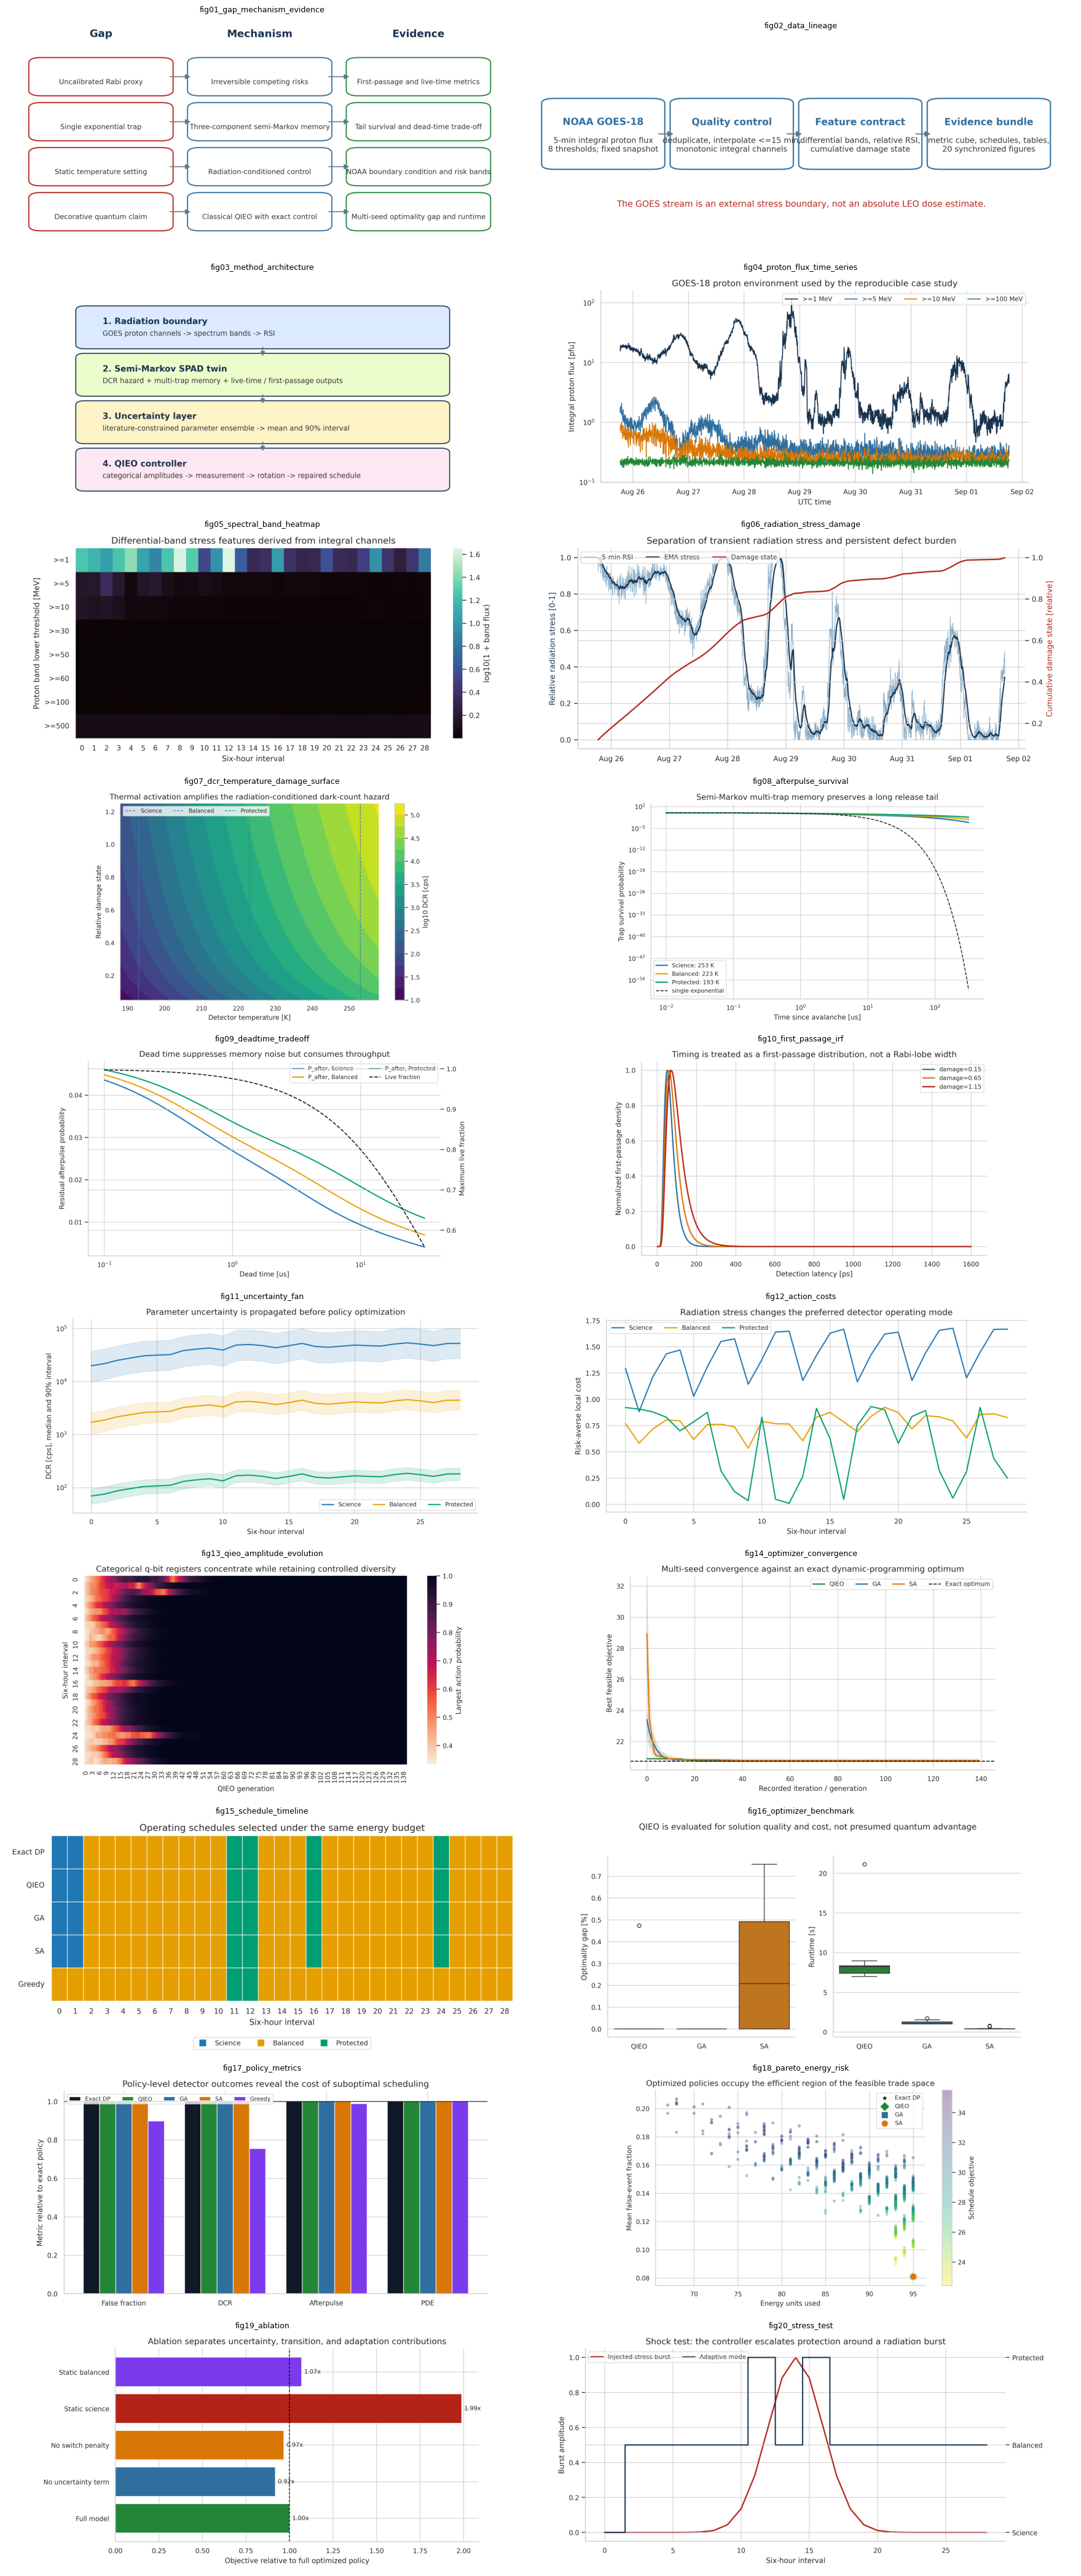

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
fig_paths = sorted(pathlib.Path('/content/radiant_spad/figures').glob('fig*.png'))
fig, axes = plt.subplots(10, 2, figsize=(18, 42))
for ax, path in zip(axes.ravel(), fig_paths):
    ax.imshow(Image.open(path))
    ax.set_title(path.stem, fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()


## Export the complete evidence bundle

The archive contains figures, per-seed optimizer traces, schedules, block features, policy metrics, and the JSON summary.

In [ ]:
import shutil
archive = shutil.make_archive('/content/RADIANT_SPAD_evidence', 'zip', '/content/radiant_spad')
print('Created', archive)
try:
    from google.colab import files
    # Uncomment to download: files.download(archive)
except ImportError:
    pass


Created /content/RADIANT_SPAD_evidence.zip
